# Chapitre 1 - Cours 3 : cloud ou auto-hébergement

Deuxième grand compromis du chapitre : faut-il faire tourner soi-même ses systèmes de
données, ou les louer à un fournisseur de cloud ? La question est d'abord économique et
organisationnelle, mais le cloud a aussi transformé la **manière de construire** les
systèmes de données : stockage objet, séparation du stockage et du calcul,
multi-location. Ce notebook couvre la section *Cloud Versus Self-Hosting* : *Pros and
Cons of Cloud Services*, *Cloud Native System Architecture* (*Layering of cloud
services*, *Separation of storage and compute*) et *Operations in the Cloud Era*.

**Plan.**

1. Construire ou acheter, opérer ou externaliser : le spectre des choix.
2. Le coût : un modèle de coût total selon la taille et la variabilité de la charge.
3. Le contrôle : ce que l'on cède au fournisseur, et le prix de la sortie.
4. L'architecture cloud native : empilement des services et ordres de grandeur des
   couches de stockage.
5. Séparer stockage et calcul : disques éphémères, disques virtuels, caches.
6. La multi-location : mutualisation et voisins bruyants.
7. L'exploitation à l'ère du cloud : de la planification de capacité à la planification
   financière.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Construire ou acheter, opérer ou externaliser (section *Cloud Versus Self-Hosting*)

Pour toute activité, une organisation se demande si elle la fait elle-même ou si elle
l'achète. Règle empirique citée par le livre : ce qui relève du **cœur de métier** ou d'un
**avantage concurrentiel** se fait en interne ; ce qui est banal, routinier, se confie à
un fournisseur (presque personne ne fabrique ses propres processeurs). Pour le logiciel,
deux décisions se superposent : **qui écrit** le logiciel, et **qui le déploie et
l'exploite**.

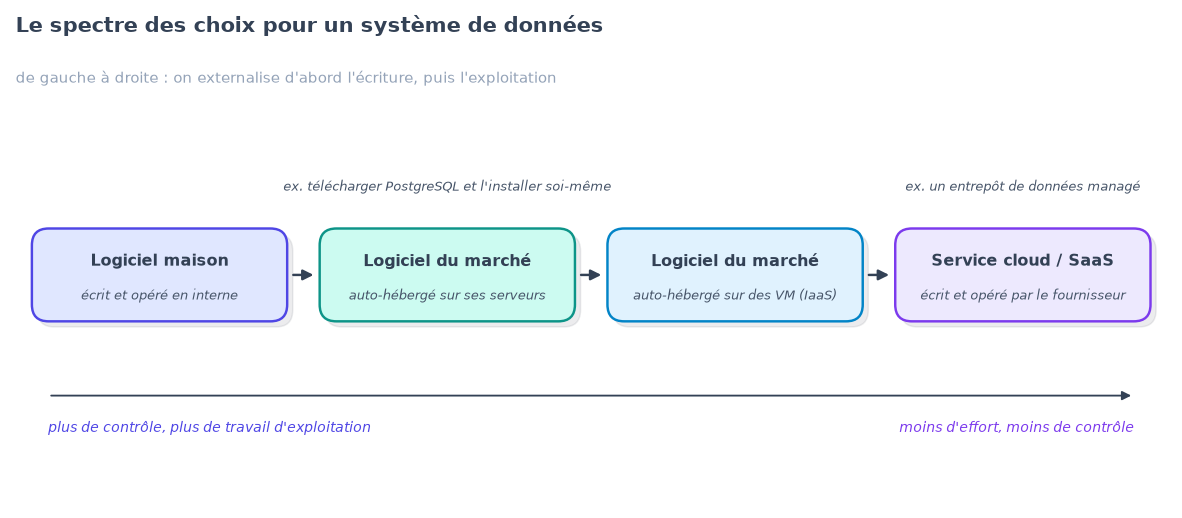

In [2]:
d = Diagram(12.5, 4.4, title="Le spectre des choix pour un système de données",
            subtitle="de gauche à droite : on externalise d'abord l'écriture, puis l'exploitation")
specs = [("custom", "Logiciel maison", "écrit et opéré en interne", INDIGO),
         ("onprem", "Logiciel du marché", "auto-hébergé sur ses serveurs", TEAL),
         ("iaas", "Logiciel du marché", "auto-hébergé sur des VM (IaaS)", SKY),
         ("saas", "Service cloud / SaaS", "écrit et opéré par le fournisseur", VIOLET)]
for i, (k, t, sub, c) in enumerate(specs):
    d.box(k, 1.6 + i * 3.1, 2.5, t, sub=sub, color=c, w=2.75, h=1.0)
for a, b in zip(specs, specs[1:]):
    d.arrow(a[0], b[0])
d.line([(0.4, 1.2), (12.1, 1.2)], color=SLATE, style="solid")
d.note(0.4, 0.85, "plus de contrôle, plus de travail d'exploitation", ha="left", color=INDIGO)
d.note(12.1, 0.85, "moins d'effort, moins de contrôle", ha="right", color=VIOLET)
d.note(4.7, 3.45, "ex. télécharger PostgreSQL et l'installer soi-même", fontsize=8.5)
d.note(10.9, 3.45, "ex. un entrepôt de données managé", fontsize=8.5)
d.show()

Au milieu du spectre, on trouve le logiciel du marché (libre ou commercial) qu'on
**auto-héberge** : sur son propre matériel (« on premises », même si le serveur est dans
une baie louée), ou sur une machine virtuelle louée à un cloud (*infrastructure as a
service*, IaaS). Il existe des points intermédiaires (un logiciel libre modifié, par
exemple). Le choix de l'outillage de déploiement (orchestrateur comme Kubernetes) est
laissé de côté par le livre : il pèse moins sur l'architecture des données.

> **À retenir.** Deux questions distinctes : qui écrit le logiciel, et qui l'exploite.
> On garde en interne ce qui fait la différence, on achète le reste.